# 07 - Final Comparison: Random Forest vs XGBoost

## 1. Objective

Notebook 06 evaluated only the model selected in notebook 05 (XGBoost) against persistence on the test set. To answer the main question of the project, **how does bagging (Random Forest) compare with boosting (XGBoost) on unseen Sri Lankan dengue data?**, both ensembles must be evaluated in exactly the same way.

This notebook:
1. Retrains the **Random Forest setting chosen in notebook 05** (200 trees, `min_samples_leaf = 10`) on the same training period as the final XGBoost model (target weeks 2007-2023).
2. Loads the **final XGBoost model saved in notebook 06** (not retrained, so it is exactly the evaluated model).
3. Scores **Random Forest, XGBoost and persistence on the identical test rows** (target weeks 2024-2026).
4. Investigates **why XGBoost does worse than persistence** on the test set: by year, by district, and at outbreak peaks.
5. Saves the final Random Forest model and the results for the dashboard.

**Rules that keep the test fair**
- Both models' settings were fixed in notebook 05 using only the 2023 validation year. Nothing is tuned or changed here after looking at the test scores.
- The test set and the leakage check are the same as in notebook 06.
- Notebook 06 and its results are **not changed**. Everything in this notebook is a **new result**, added afterwards.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from xgboost import XGBRegressor

TRAIN_PATH = Path("../dataset/processed/train.csv")
TEST_PATH = Path("../dataset/processed/test.csv")
CLEANED_PATH = Path("../dataset/processed/02_cleaned_weekly_data.csv")
CONFIG_PATH = Path("../models/05_selected_model.json")
XGB_MODEL_PATH = Path("../models/06_final_xgboost_model.json")

RF_MODEL_PATH = Path("../models/07_final_random_forest_model.joblib")
RESULTS_PATH = Path("../models/07_final_test_results.json")
PREDICTIONS_PATH = Path("../models/07_test_predictions.csv")

config = json.loads(CONFIG_PATH.read_text())
FEATURES = config["features"]
TARGET = config["target"]
RANDOM_STATE = config["random_state"]
XGB_PARAMS = config["params"]
assert config["selected_model"] == "XGBoost"

# Random Forest setting selected on the 2023 validation year in notebook 05
# ("200 trees, min_samples_leaf=10", validation MAE 18.14). Fixed before the test set is used.
RF_PARAMS = {"n_estimators": 200, "min_samples_leaf": 10}

MODELS = ["Persistence", "Random Forest", "XGBoost"]

# chart colours (the same as notebooks 04-06)
COLORS = {"Persistence": "#898781", "Random Forest": "#2a78d6", "XGBoost": "#1baf7a"}
INK, GRID = "#0b0b0b", "#e4e3df"

## 2. Load the data (same steps as notebook 06)

- `train.csv`: target weeks 2007-2023. `test.csv`: target weeks 2024-2026.
- **Leakage check:** rows whose current week (`is_imputed`) or target week (`target_imputed`) was interpolated in notebook 02 are removed. An interpolated value was calculated from the following week, i.e. from the answer.
- The test set must contain exactly the **3,508 rows** used in notebook 06, so all three models are scored on the same observations.

In [2]:
train = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])
test = pd.read_csv(TEST_PATH, parse_dates=["start_date", "target_date"])

train_leaky = train["is_imputed"] | train["target_imputed"]
test_leaky = test["is_imputed"] | test["target_imputed"]
train = train[~train_leaky].reset_index(drop=True)
test = test[~test_leaky].reset_index(drop=True)
print("removed interpolated rows: train", train_leaky.sum(), "| test", test_leaky.sum())

# safety checks
assert train["target_date"].max() < test["target_date"].min()          # all training weeks come first
assert train[FEATURES + [TARGET]].notna().all().all() and test[FEATURES + [TARGET]].notna().all().all()
assert TARGET not in FEATURES and "target_log_next" not in FEATURES     # the answer is not an input
assert (test["target_date"] - test["start_date"] == pd.Timedelta(days=7)).all()  # target = the following week
assert len(test) == 3508                                                 # same test rows as notebook 06

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET].to_numpy()

print("training rows:", len(train), "| target weeks", train["target_date"].min().date(), "to", train["target_date"].max().date())
print("test rows:    ", len(test), "| target weeks", test["target_date"].min().date(), "to", test["target_date"].max().date())

removed interpolated rows: train 52 | test 106
training rows: 21684 | target weeks 2007-12-29 to 2023-12-30
test rows:     3508 | target weeks 2024-01-06 to 2026-08-29


## 3. Check: the Random Forest setting reproduces notebook 05

Before using the setting, it is retrained exactly as in notebook 05 (training target weeks 2007-2022, validation 2023). It must give the validation MAE that notebook 05 recorded in `05_selected_model.json`. This confirms that the right setting is used and that the result can be reproduced.

In [3]:
target_year = train["target_date"].dt.year
fit_part = train[target_year < config["validation_year"]]
valid_part = train[target_year == config["validation_year"]]

rf_check = RandomForestRegressor(**RF_PARAMS, random_state=RANDOM_STATE, n_jobs=-1)
rf_check.fit(fit_part[FEATURES], fit_part[TARGET])
check_mae = mean_absolute_error(valid_part[TARGET], rf_check.predict(valid_part[FEATURES]))

recorded_mae = config["validation_scores"]["Random Forest"]["MAE"]
print(f"validation MAE now: {check_mae:.3f} | recorded in notebook 05: {recorded_mae}")
assert abs(check_mae - recorded_mae) < 0.0005

validation MAE now: 18.139 | recorded in notebook 05: 18.139


## 4. Train the final Random Forest

Same training rows as the final XGBoost model in notebook 06: **all** of `train.csv` (target weeks 2007-2023), with the leaky rows removed.

**Reproducibility note:** the trees are built in parallel (`n_jobs=-1`) but with a fixed `random_state`, so they are identical every run. When *predicting* in parallel, the 200 tree outputs are added up in a slightly different order each time, which changes results in about the 13th decimal place. Prediction is therefore switched to a single thread (`n_jobs=1`), which makes every prediction exactly repeatable.

In [4]:
final_rf = RandomForestRegressor(**RF_PARAMS, random_state=RANDOM_STATE, n_jobs=-1)
final_rf.fit(X_train, y_train)
final_rf.set_params(n_jobs=1)  # exactly repeatable predictions

train_mae = mean_absolute_error(y_train, final_rf.predict(X_train))
print("trained on", len(X_train), "rows | training MAE:", round(train_mae, 2))

trained on 21684 rows | training MAE: 8.5


## 5. Load the final XGBoost model from notebook 06

The saved model is loaded, so the evaluated XGBoost is exactly the one from notebook 06. As a reproducibility check, XGBoost is also retrained with the same settings and seed; it must give the same predictions as the saved file.

In [5]:
final_xgb = XGBRegressor()
final_xgb.load_model(XGB_MODEL_PATH)

xgb_check = XGBRegressor(**XGB_PARAMS, random_state=RANDOM_STATE, n_jobs=-1)
xgb_check.fit(X_train, y_train)
assert np.allclose(xgb_check.predict(X_test), final_xgb.predict(X_test))
print("saved XGBoost model = retrained XGBoost model (same predictions)")

saved XGBoost model = retrained XGBoost model (same predictions)


## 6. Predict the test weeks

- **Persistence:** next week = this week (`current_week_cases`).
- **Random Forest:** the average of 200 trees. Each leaf holds real past counts, so it cannot predict below 0 (or above the largest training value).
- **XGBoost:** clipped at 0, as in notebooks 05 and 06, because boosting adds up corrections and can go negative.

In [6]:
predictions = {
    "Persistence": test["current_week_cases"].to_numpy(dtype=float),
    "Random Forest": final_rf.predict(X_test),
    "XGBoost": np.clip(final_xgb.predict(X_test), 0, None),
}

# all three models predict exactly the same test rows
assert all(len(p) == len(test) for p in predictions.values())
assert (predictions["Random Forest"] >= 0).all()

# the XGBoost predictions must match notebook 06's test score
assert round(mean_absolute_error(y_test, predictions["XGBoost"]), 2) == 13.22

## 7. Final test results (2024-2026)

MAE and RMSE are in cases per district-week (lower is better). The last two columns show the change compared with persistence: **negative = smaller error than persistence**.

In [7]:
def evaluate(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted), "RMSE": root_mean_squared_error(actual, predicted)}


def score_table(rows):
    """MAE and RMSE of every model on the selected test rows, plus the change vs persistence."""
    table = pd.DataFrame({name: evaluate(y_test[rows], predictions[name][rows]) for name in MODELS}).T
    table["MAE vs persistence (%)"] = 100 * (table["MAE"] / table.loc["Persistence", "MAE"] - 1)
    table["RMSE vs persistence (%)"] = 100 * (table["RMSE"] / table.loc["Persistence", "RMSE"] - 1)
    return table


all_rows = np.ones(len(test), dtype=bool)
test_results = score_table(all_rows)
test_results.round(2)

,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
Persistence,12.63,29.93,0.00,0.00
Random Forest,12.53,33.63,-0.80,12.37
XGBoost,13.22,39.19,4.63,30.94


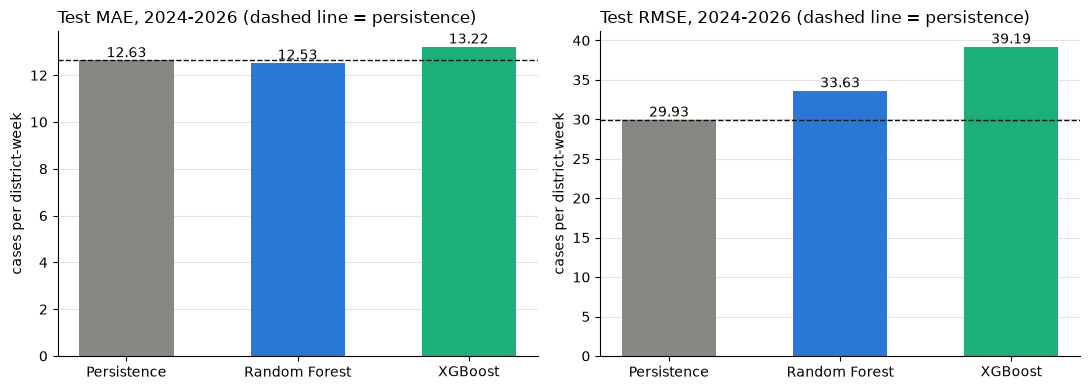

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    values = test_results[metric].to_numpy()
    ax.bar(MODELS, values, color=[COLORS[name] for name in MODELS], width=0.55)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.axhline(test_results.loc["Persistence", metric], color=INK, linewidth=1, linestyle="--")
    ax.set_title(f"Test {metric}, 2024-2026 (dashed line = persistence)", loc="left")
    ax.set_ylabel("cases per district-week")
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What the test results show**

- **Random Forest has the lowest test MAE** (12.53), slightly below persistence (12.63, **-0.8%**). **XGBoost has the highest** (13.22, **+4.6%**).
- **On RMSE, both ensembles are worse than persistence**: Random Forest 33.63 (**+12%**) and XGBoost 39.19 (**+31%**). RMSE punishes large misses, so both models make some very large errors that persistence does not (section 8.3).
- **Random Forest beats XGBoost on both metrics.** On the 2023 validation year the order was the other way round (XGBoost 18.10 vs Random Forest 18.14 MAE), but that gap was tiny.
- Overall, **neither ensemble convincingly beats the persistence baseline** on the test years. The Random Forest's MAE advantage is under 1% and comes with a higher RMSE.

### Validation (2023) vs test (2024-2026)

The 2023 validation scores from notebook 05 next to the new test scores. The test period includes the very large 2026 outbreak, so the fair comparison between periods is the **change vs persistence**, not the raw error.

In [9]:
valid_scores = config["validation_scores"]
valid_table = pd.DataFrame(valid_scores).T.loc[MODELS]

period_comparison = pd.DataFrame({
    "validation MAE (2023)": valid_table["MAE"],
    "validation MAE vs persistence (%)": 100 * (valid_table["MAE"] / valid_table.loc["Persistence", "MAE"] - 1),
    "test MAE (2024-26)": test_results["MAE"],
    "test MAE vs persistence (%)": test_results["MAE vs persistence (%)"],
    "validation RMSE (2023)": valid_table["RMSE"],
    "test RMSE (2024-26)": test_results["RMSE"],
})
period_comparison.round(2)

,validation MAE (2023),validation MAE vs persistence (%),test MAE (2024-26),test MAE vs persistence (%),validation RMSE (2023),test RMSE (2024-26)
Persistence,18.17,0.00,12.63,0.00,41.82,29.93
Random Forest,18.14,-0.17,12.53,-0.80,42.32,33.63
XGBoost,18.10,-0.39,13.22,4.63,41.34,39.19


On 2023 the three models were within 0.4% of each other in MAE. On the test years the differences are larger, and the ranking changed: XGBoost went from best to worst. **A model should not be called the best because it won a close validation comparison on one year.** This is the reason for keeping an untouched test set.

## 8. Why does XGBoost do worse? Diagnostics

### 8.1 Results by test year

In [10]:
test_year = test["target_date"].dt.year.to_numpy()
year_rows = []
for year in sorted(np.unique(test_year)):
    rows = test_year == year
    row = {"year": int(year), "rows": int(rows.sum()), "mean weekly cases": y_test[rows].mean()}
    for name in MODELS:
        row[f"{name} MAE"] = mean_absolute_error(y_test[rows], predictions[name][rows])
    for name in MODELS:
        row[f"{name} RMSE"] = root_mean_squared_error(y_test[rows], predictions[name][rows])
    year_rows.append(row)

by_year = pd.DataFrame(year_rows).set_index("year")
by_year.round(2)

,rows,mean weekly cases,Persistence MAE,Random Forest MAE,XGBoost MAE,Persistence RMSE,Random Forest RMSE,XGBoost RMSE
year,,,,,,,,
2024,1352,37.14,10.45,9.53,9.47,21.15,18.73,20.62
2025,1352,37.57,8.68,8.31,8.27,15.20,15.05,14.77
2026,804,98.86,22.93,24.66,27.82,52.61,62.96,74.97


- **2024 and 2025** (moderate years, about 37 cases per district-week): **both ensembles beat persistence** in MAE (Random Forest about -9% and -4%, XGBoost about -9% and -5%). XGBoost and Random Forest are almost equal; in 2024 the Random Forest has the lowest RMSE of all three (18.73).
- **2026** (very large outbreak, about 99 cases per district-week, data until August): **both ensembles are worse than persistence**. Random Forest MAE 24.66 (about +8%), XGBoost 27.82 (about +21%). XGBoost's 2026 RMSE (74.97) is much higher than Random Forest's (62.96) and persistence's (52.61).

So the poor overall XGBoost result comes mainly from **2026**. In normal years both ensembles add a small, real improvement over persistence.

### 8.2 Results by district

MAE per district (the 26 reporting areas), sorted by the average number of cases. `best` is the model with the lowest MAE in that district.

In [11]:
district_rows = []
for district in sorted(test["district"].unique()):
    rows = (test["district"] == district).to_numpy()
    row = {"district": district, "mean weekly cases": y_test[rows].mean()}
    for name in MODELS:
        row[name] = mean_absolute_error(y_test[rows], predictions[name][rows])
    district_rows.append(row)

by_district = pd.DataFrame(district_rows).set_index("district").sort_values("mean weekly cases", ascending=False)
by_district["best"] = by_district[MODELS].idxmin(axis=1)
by_district.round(2)

,mean weekly cases,Persistence,Random Forest,XGBoost,best
district,,,,,
Colombo,305.26,49.43,54.14,58.12,Persistence
Gampaha,205.55,38.54,41.82,41.55,Persistence
Kandy,108.41,24.35,23.44,27.04,Random Forest
Kalutara,89.58,22.36,23.35,29.56,Persistence
Ratnapura,88.53,19.96,19.35,17.97,XGBoost
Galle,68.19,16.05,14.37,16.48,Random Forest
Matara,64.40,18.55,17.08,19.10,Random Forest
Jaffna,56.29,16.52,14.31,15.22,Random Forest
Kurunegala,45.71,12.72,12.21,12.39,Random Forest


In [12]:
print("districts where each model has the lowest MAE:")
print(by_district["best"].value_counts().to_string())
print()
print("Random Forest beats persistence in", (by_district["Random Forest"] < by_district["Persistence"]).sum(), "of 26 districts")
print("XGBoost beats persistence in      ", (by_district["XGBoost"] < by_district["Persistence"]).sum(), "of 26 districts")
print("Random Forest beats XGBoost in    ", (by_district["Random Forest"] < by_district["XGBoost"]).sum(), "of 26 districts")

districts where each model has the lowest MAE:
best
Random Forest    15
Persistence       6
XGBoost           5

Random Forest beats persistence in 19 of 26 districts
XGBoost beats persistence in       16 of 26 districts
Random Forest beats XGBoost in     18 of 26 districts


- **Random Forest has the lowest MAE in 15 of the 26 reporting areas**, persistence in 6 and XGBoost in 5. Random Forest beats persistence in 19 areas and XGBoost in 18.
- **Persistence is best in the three largest districts** (Colombo, Gampaha, Kalutara), where the 2026 outbreak was largest. Because the MAE is an average over all district-weeks, these big districts have a large effect on the overall score: the ensembles help in most areas, but lose more in the few areas with very large counts.

### 8.3 Outbreak peaks: do the models overestimate?

The very high weeks are split by what happened next:
- **current week > 500, next week higher:** the outbreak is still growing.
- **current week > 500, next week lower or equal:** the peak has been reached or passed.

*Mean error* = average of (predicted - actual). **Positive = the model predicts too many cases.**

In [13]:
current = test["current_week_cases"].to_numpy()
high = current > 500
rising = y_test > current

groups = {
    "current week > 500, next week higher": high & rising,
    "current week > 500, next week lower or equal": high & ~rising,
    "all other weeks (current week <= 500)": ~high,
}

peak_rows = []
for label, rows in groups.items():
    row = {"group": label, "district-weeks": int(rows.sum())}
    for name in MODELS:
        row[f"{name} mean error"] = (predictions[name][rows] - y_test[rows]).mean()
    for name in MODELS:
        row[f"{name} MAE"] = mean_absolute_error(y_test[rows], predictions[name][rows])
    peak_rows.append(row)

peaks = pd.DataFrame(peak_rows).set_index("group")
peaks.round(1)

,district-weeks,Persistence mean error,Random Forest mean error,XGBoost mean error,Persistence MAE,Random Forest MAE,XGBoost MAE
group,,,,,,,
"current week > 500, next week higher",9,-191.9,-33.9,-201.3,191.9,184.2,217.4
"current week > 500, next week lower or equal",28,161.8,197.1,237.5,161.8,211.8,262.1
all other weeks (current week <= 500),3471,0.6,0.6,0.8,11.0,10.5,10.7


In [14]:
share = {}
for name in MODELS:
    squared_error = (predictions[name] - y_test) ** 2
    share[name] = 100 * squared_error[high].sum() / squared_error.sum()

print(f"{high.sum()} district-weeks with more than 500 cases ({100 * high.mean():.1f}% of test rows)")
print("share of each model's total squared error that comes from these weeks:")
for name, value in share.items():
    print(f"  {name:14s} {value:.1f}%")

37 district-weeks with more than 500 cases (1.1% of test rows)
share of each model's total squared error that comes from these weeks:
  Persistence    50.4%
  Random Forest  62.8%
  XGBoost        67.7%


The 10 largest XGBoost errors, with the Random Forest prediction for the same week:

In [15]:
largest = test[["district", "start_date", "current_week_cases", TARGET]].copy()
largest["Random Forest"] = predictions["Random Forest"].round()
largest["XGBoost"] = predictions["XGBoost"].round()
largest["XGBoost error"] = (predictions["XGBoost"] - y_test).round()
largest.reindex(largest["XGBoost error"].abs().sort_values(ascending=False).index).head(10)

,district,start_date,current_week_cases,cases_next,Random Forest,XGBoost,XGBoost error
3304,Colombo,2026-07-04,1625,1330,1599.0,2265.0,935.0
3436,Gampaha,2026-08-08,567,48,581.0,780.0,732.0
3336,Kalutara,2026-07-11,592,499,628.0,1087.0,588.0
3363,Kandy,2026-07-18,567,428,563.0,968.0,540.0
3254,Gampaha,2026-06-20,1294,1439,1556.0,1045.0,-394.0
3362,Kalutara,2026-07-18,499,379,410.0,754.0,375.0
3460,Colombo,2026-08-15,466,200,409.0,549.0,349.0
34,Jaffna,2024-01-06,805,595,733.0,928.0,333.0
86,Jaffna,2024-01-20,746,483,724.0,814.0,331.0
3258,Kalutara,2026-06-20,551,866,421.0,536.0,-330.0


### 8.4 What did the models learn about big weeks?

Tree models learn from the training years. The table counts the training weeks with more than 500 cases in the current week and shows how next week compared with the current week, split by whether the count was **rising** (`weekly_case_change > 0`) or not. The same is shown for the test years.

In [16]:
def big_week_behaviour(data, label):
    big = data[data["current_week_cases"] > 500]
    rising_now = big["weekly_case_change"] > 0
    ratio = big[TARGET] / big["current_week_cases"]
    return {
        "period": label,
        "weeks > 500": len(big),
        "of which in 2017": int((big["target_date"].dt.year == 2017).sum()),
        "rising now: mean next/current": ratio[rising_now].mean(),
        "falling now: mean next/current": ratio[~rising_now].mean(),
    }

pd.DataFrame([big_week_behaviour(train, "training 2007-2023"), big_week_behaviour(test, "test 2024-2026")]).set_index("period").round(2)

,weeks > 500,of which in 2017,rising now: mean next/current,falling now: mean next/current
period,,,,
training 2007-2023,99,69,0.96,0.90
test 2024-2026,37,0,0.88,0.93


### 8.5 Looking inside the largest XGBoost error

The largest error is Colombo, input week starting 2026-07-04: 1,625 cases this week, 1,330 the next week, but XGBoost predicted about 2,265.

XGBoost can split a prediction into **contributions** from each feature (`pred_contribs=True`): the prediction = the starting value (`bias`) + the sum of the contributions. The training weeks with the most similar situation (more than 1,200 cases) are shown underneath.

In [17]:
import xgboost as xgb_lib

peak_row = test[(test["district"] == "Colombo") & (test["start_date"] == "2026-07-04")]
contributions = final_xgb.get_booster().predict(xgb_lib.DMatrix(peak_row[FEATURES]), pred_contribs=True)[0]
breakdown = pd.DataFrame({
    "feature value": list(peak_row[FEATURES].iloc[0]) + [None],
    "contribution (cases)": contributions,
}, index=FEATURES + ["bias (starting value)"]).sort_values("contribution (cases)", ascending=False)

print("XGBoost prediction:", round(contributions.sum()), "| Random Forest:",
      round(final_rf.predict(peak_row[FEATURES])[0]), "| actual next week:", int(peak_row[TARGET].iloc[0]))
breakdown.round(1)

XGBoost prediction: 2265 | Random Forest: 1599 | actual next week: 1330


,feature value,contribution (cases)
weekly_case_change,361.0,758.700012
current_week_cases,1625.0,623.500000
previous_week_cases,1264.0,396.899994
seasonal_week_cos,-1.0,176.800003
previous_3_weeks_cases,1138.0,169.899994
moving_average_8_weeks,906.2,100.400002
bias (starting value),NaN,32.200001
moving_average_4_weeks,1291.2,27.000000
district_code,4.0,25.600000
previous_2_weeks_cases,1138.0,4.100000


In [18]:
# training weeks with more than 1,200 cases: all from the 2017 epidemic
train.loc[train["current_week_cases"] > 1200,
          ["district", "start_date", "previous_week_cases", "current_week_cases", "weekly_case_change", TARGET]].sort_values("start_date")

,district,start_date,previous_week_cases,current_week_cases,weekly_case_change,cases_next
12874,Colombo,2017-06-17,1032,1267,235,1338
12900,Colombo,2017-06-24,1267,1338,71,1779
12902,Gampaha,2017-06-24,1139,1444,305,1802
12926,Colombo,2017-07-01,1338,1779,441,1762
12928,Gampaha,2017-07-01,1444,1802,358,2631
12952,Colombo,2017-07-08,1779,1762,-17,1972
12954,Gampaha,2017-07-08,1802,2631,829,2471
12978,Colombo,2017-07-15,1762,1972,210,1958
12980,Gampaha,2017-07-15,2631,2471,-160,2135
13004,Colombo,2017-07-22,1972,1958,-14,1713


**What the peak analysis shows**

- Only **37 district-weeks** (1.1% of the test rows) had more than 500 cases, but they produce **68% of XGBoost's squared error** and 63% of the Random Forest's (persistence: 50%).
- **After a peak (28 weeks)** every method predicts too many cases, because the count is about to fall. Persistence overestimates by about 162 cases on average, the Random Forest by about 197 and **XGBoost by about 238**. **XGBoost systematically overestimates at and after the top of an outbreak.**
- **While the outbreak is still growing (9 weeks)** persistence and XGBoost underestimate by about 190-200 cases. The Random Forest is much closer on average (-34), although its MAE is still large (184).
- **The cause (8.4, 8.5):** only 99 training weeks had more than 500 cases, and 69 of them were from the 2017 epidemic. The few training weeks above 1,200 cases are all Colombo and Gampaha in June-July 2017, when large weekly jumps (+300 to +800) were followed by even higher counts (for example Gampaha 1,802 -> 2,631). In July 2026, Colombo jumped from 1,264 to 1,625 cases. XGBoost's breakdown shows that the **`weekly_case_change` of +361 alone added about +759 cases**, and the high current and previous weeks added several hundred more. The prediction (about 2,265) was far above the actual 1,330.
- The second-largest XGBoost error (Gampaha, 567 cases followed by 48) falls in the late-August 2026 weeks that notebook 02 flagged as a possible reporting drop. Part of that "error" may be incomplete data rather than a bad forecast; it is kept, as in notebook 06.
- **Why the Random Forest is more careful:** every Random Forest leaf must contain at least 10 training rows, and the prediction is an **average of real past values**, so it cannot go beyond what similar past weeks did, and a handful of extreme 2017 weeks are mixed with other weeks. XGBoost **adds up** many small corrections. With shallow trees (depth 2) each tree mostly looks at one or two features, so correlated signals (current week high, previous week high, big jump) each add their own increase, and together they overshoot. This matches what is usually said about the two methods: bagging reduces variance, while boosting reduces bias but can fit rare patterns more strongly.

## 9. Actual vs predicted

### 9.1 Colombo and Gampaha, 2024-2026

The two districts with the most cases.

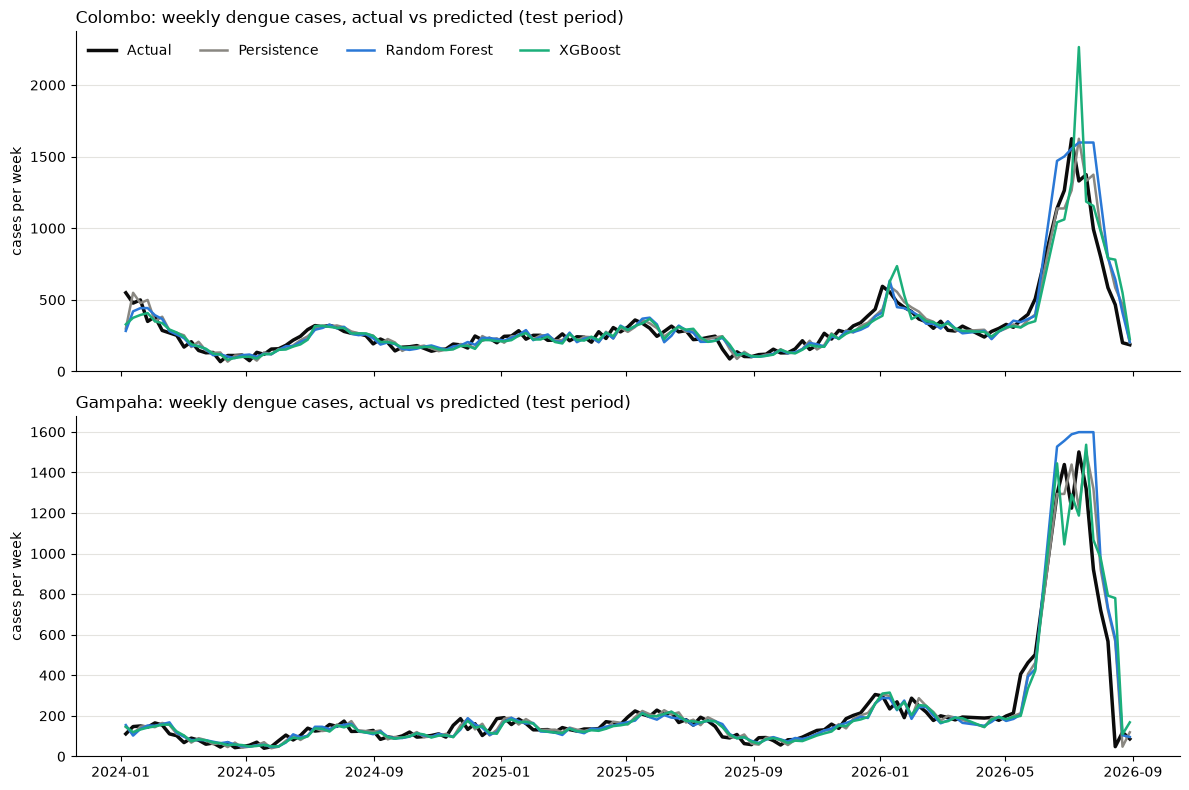

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, district in zip(axes, ["Colombo", "Gampaha"]):
    rows = (test["district"] == district).to_numpy()
    dates = test.loc[rows, "target_date"]
    ax.plot(dates, y_test[rows], color=INK, linewidth=2.5, label="Actual")
    for name in MODELS:
        ax.plot(dates, predictions[name][rows], color=COLORS[name], linewidth=1.8, label=name)
    ax.set_title(f"{district}: weekly dengue cases, actual vs predicted (test period)", loc="left")
    ax.set_ylabel("cases per week")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color=GRID)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, ncol=4)
plt.tight_layout()
plt.show()

### 9.2 Predicted vs actual, all test rows

Each dot is one district-week. Dots on the dashed diagonal are perfect predictions; dots **above** it are overestimates. Both axes use a log-like (symlog) scale so small and large districts are visible.

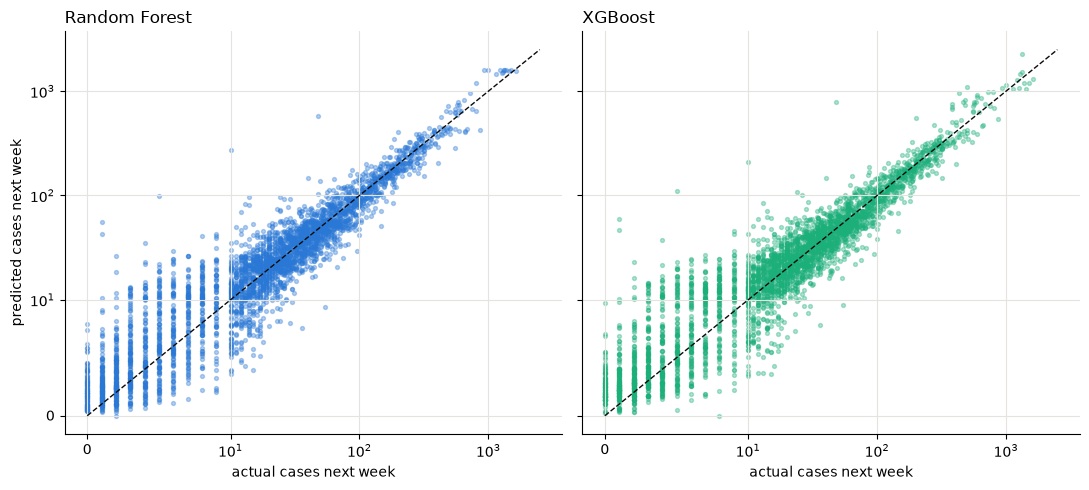

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    ax.scatter(y_test, predictions[name], s=8, alpha=0.35, color=COLORS[name])
    ax.plot([0, 2500], [0, 2500], color=INK, linewidth=1, linestyle="--")
    ax.set_xscale("symlog", linthresh=10)
    ax.set_yscale("symlog", linthresh=10)
    ax.set_title(name, loc="left")
    ax.set_xlabel("actual cases next week")
    ax.grid(color=GRID)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("predicted cases next week")
plt.tight_layout()
plt.show()

## 10. Sensitivity check: duplicated weeks

Notebook 02 found four pairs of weeks where **all 26 counts are identical** to the week before (`dup_week`); most likely the same report was copied twice. They were kept because it is not known which copy is real. Two pairs are in the test period (2025 weeks 7/8 and 2026 weeks 25/26).

For the test rows whose current week **and** target week are such a copy, the target equals the current week, so persistence gets an error of exactly 0, which is probably not a real forecast success.

**This check does not replace the official test results above.** It re-scores the same predictions without the rows whose current or target week is a flagged duplicate. The rule comes from the data-quality flag of notebook 02 and is applied to all three models in the same way; no model or setting is changed.

In [21]:
cleaned = pd.read_csv(CLEANED_PATH, parse_dates=["start_date"])
dup_dates = set(cleaned.loc[cleaned["dup_week"], "start_date"])

touches_dup = (test["start_date"].isin(dup_dates) | test["target_date"].isin(dup_dates)).to_numpy()
copied_target = (test["start_date"].isin(dup_dates) & test["target_date"].isin(dup_dates)).to_numpy()

print("test rows that use a duplicated week:", touches_dup.sum())
print("of which the target is a copy of the current week:", copied_target.sum(),
      "| persistence error on them:", np.abs(predictions["Persistence"][copied_target] - y_test[copied_target]).sum())

sensitivity = score_table(~touches_dup)
sensitivity.round(2)

test rows that use a duplicated week: 130
of which the target is a copy of the current week: 52 | persistence error on them: 0.0


,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
Persistence,12.54,29.24,0.00,0.00
Random Forest,12.04,31.51,-3.97,7.76
XGBoost,12.81,38.11,2.12,30.31


**What the sensitivity check shows**

- 130 test rows use a duplicated week; in 52 of them the target is an exact copy of the current week, so persistence is "perfect" on them.
- Without these rows, **Random Forest's MAE advantage over persistence grows from -0.8% to -4.0%**, while XGBoost is still worse than persistence (+2.1%). Both ensembles remain worse on RMSE.
- The duplicated weeks therefore make persistence look somewhat better than it is, but they **do not change the conclusions**: Random Forest is ahead of XGBoost, and neither has a clearly lower RMSE than persistence. The official test results in section 7 stay as they are.

## 11. Feature importance

Two kinds of importance are shown:

1. **Built-in importance** (computed from the training data):
   - Random Forest: **impurity-based** importance (how much each feature's splits reduce the squared error, averaged over the trees).
   - XGBoost: **gain** (average error reduction of the splits that use the feature).
2. **Permutation importance** (computed on the test set): shuffle one feature's values, so it no longer carries information, and measure how much the test MAE gets worse. Repeated 5 times per feature and averaged.

**Cautions**
- Importance shows what the model **uses**, not what **causes** dengue cases.
- The lag and moving-average features are strongly correlated. Correlated features **share** the importance, so one can look unimportant only because another carries the same information.
- Impurity and gain importance are measured on training data and favour features with many distinct values; permutation importance on unseen data is usually more reliable.
- Built-in importances of the two models are measured on different scales and are not directly comparable; compare the **ranking**.

In [22]:
xgb_gain = pd.Series(final_xgb.get_booster().get_score(importance_type="gain")).reindex(FEATURES).fillna(0)

builtin = pd.DataFrame({
    "Random Forest (impurity)": final_rf.feature_importances_,
    "XGBoost (gain)": xgb_gain / xgb_gain.sum(),
}, index=FEATURES)


def predict_with(name, X):
    if name == "Random Forest":
        return final_rf.predict(X)
    return np.clip(final_xgb.predict(X), 0, None)


rng = np.random.default_rng(RANDOM_STATE)
permutation = {}
for name in ["Random Forest", "XGBoost"]:
    base_mae = mean_absolute_error(y_test, predictions[name])
    increase = {}
    for feature in FEATURES:
        repeats = []
        for _ in range(5):
            X_shuffled = X_test.copy()
            X_shuffled[feature] = rng.permutation(X_shuffled[feature].to_numpy())
            repeats.append(mean_absolute_error(y_test, predict_with(name, X_shuffled)) - base_mae)
        increase[feature] = np.mean(repeats)
    permutation[f"{name} (test MAE increase)"] = increase

importance = builtin.join(pd.DataFrame(permutation)).sort_values("Random Forest (impurity)", ascending=False)
importance.round(3)

,Random Forest (impurity),XGBoost (gain),Random Forest (test MAE increase),XGBoost (test MAE increase)
current_week_cases,0.905,0.672,39.460,29.557
moving_average_4_weeks,0.055,0.068,9.804,6.916
previous_week_cases,0.012,0.117,1.168,6.509
moving_average_8_weeks,0.006,0.014,0.582,1.143
seasonal_week_cos,0.006,0.066,0.108,0.090
seasonal_week_sin,0.004,0.003,0.209,0.186
weekly_case_change,0.003,0.012,0.059,-0.095
previous_3_weeks_cases,0.003,0.024,0.417,0.496
previous_2_weeks_cases,0.003,0.003,0.225,0.066
seasonal_cases_previous_52_weeks,0.003,0.004,0.171,0.164


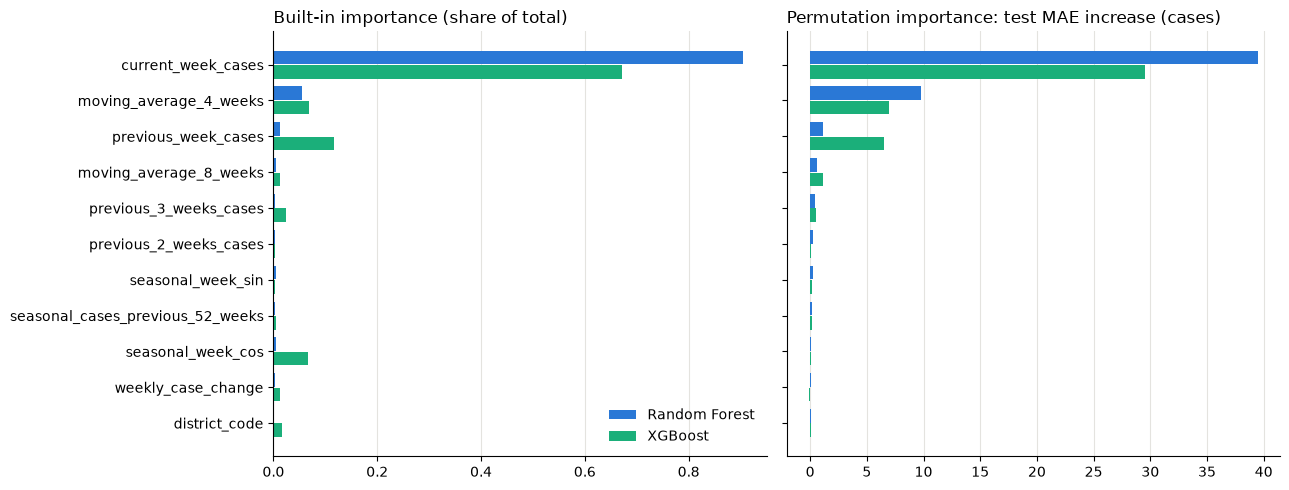

In [23]:
order = importance.sort_values("Random Forest (test MAE increase)").index
y = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
panels = [
    ("Built-in importance (share of total)", "Random Forest (impurity)", "XGBoost (gain)"),
    ("Permutation importance: test MAE increase (cases)", "Random Forest (test MAE increase)", "XGBoost (test MAE increase)"),
]
for ax, (title, rf_col, xgb_col) in zip(axes, panels):
    ax.barh(y + 0.2, importance.loc[order, rf_col], height=0.38, color=COLORS["Random Forest"], label="Random Forest")
    ax.barh(y - 0.2, importance.loc[order, xgb_col], height=0.38, color=COLORS["XGBoost"], label="XGBoost")
    ax.set_title(title, loc="left")
    ax.grid(axis="x", color=GRID)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(y, order)
axes[0].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**What the importance shows**

- Both models depend mostly on **`current_week_cases`**, then the **4-week moving average**. In other words, both have largely learned a smoothed version of the persistence rule, which explains why they are so close to it.
- **XGBoost relies more on the previous week** (permutation: +6.5 cases MAE when shuffled, Random Forest: +1.2) and on the seasonal position. It uses more of the "shape" of the recent curve.
- For XGBoost, shuffling **`weekly_case_change`** makes the test MAE slightly *better* (-0.1). The feature does not help XGBoost on the test years, which is consistent with the overshoot found in section 8.5.
- The 52-week seasonal lag and the district code contribute very little to either model.

## 12. Save the Random Forest model and the results

- **Model:** `models/07_final_random_forest_model.joblib`, saved with `joblib` (the standard way to save scikit-learn models). A joblib file should be loaded with the same scikit-learn version it was saved with; the versions are stored in the results file. It is loaded back and must give exactly the same predictions.
- **Results:** `models/07_final_test_results.json`, used by the dashboard.
- **Predictions:** `models/07_test_predictions.csv`, every test row with the actual value and the three predictions, so the results can be checked without retraining.

**Only load joblib/pickle files from a trusted source** - loading one can run code.

In [24]:
RF_MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(final_rf, RF_MODEL_PATH, compress=3)

loaded_rf = joblib.load(RF_MODEL_PATH)
assert np.array_equal(loaded_rf.predict(X_test), predictions["Random Forest"])
print("saved", RF_MODEL_PATH, f"({RF_MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print("reloaded model gives identical predictions")

saved_predictions = test[["district", "start_date", "target_date", "current_week_cases", TARGET]].rename(
    columns={TARGET: "actual_cases_next", "current_week_cases": "persistence_pred"})
saved_predictions["random_forest_pred"] = predictions["Random Forest"]
saved_predictions["xgboost_pred"] = predictions["XGBoost"]
saved_predictions.to_csv(PREDICTIONS_PATH, index=False, date_format="%Y-%m-%d")
print("saved", PREDICTIONS_PATH, saved_predictions.shape)

saved ..\models\07_final_random_forest_model.joblib (9.2 MB)
reloaded model gives identical predictions
saved ..\models\07_test_predictions.csv (3508, 7)


In [25]:
def to_dict(table):
    return {str(k): {c: float(v) for c, v in row.items()} for k, row in table.round(3).to_dict(orient="index").items()}


results = {
    "created_by": "notebooks analysis/07_final_rf_vs_xgboost_comparison.ipynb",
    "note": "New results added after notebook 06. Notebook 06 and 05_selected_model.json are unchanged.",
    "train_rows": int(len(train)),
    "test_rows": int(len(test)),
    "train_target_weeks": [str(train["target_date"].min().date()), str(train["target_date"].max().date())],
    "test_target_weeks": [str(test["target_date"].min().date()), str(test["target_date"].max().date())],
    "random_forest_params": {**RF_PARAMS, "random_state": RANDOM_STATE},
    "xgboost_params": {**XGB_PARAMS, "random_state": RANDOM_STATE},
    "test_scores": to_dict(test_results),
    "test_scores_by_year": to_dict(by_year.drop(columns="rows")),
    "sensitivity_without_duplicated_weeks": {"rows": int((~touches_dup).sum()), "scores": to_dict(sensitivity)},
    "feature_importance": to_dict(importance),
    "library_versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                         "pandas": pd.__version__, "numpy": np.__version__},
}
RESULTS_PATH.write_text(json.dumps(results, indent=2))
print("saved", RESULTS_PATH)

saved ..\models\07_final_test_results.json


## 13. Summary

**Final test results** (target weeks 2024-01-06 to 2026-08-29, the same 3,508 district-weeks for every model; both ensembles trained on target weeks 2007-2023 with settings chosen on 2023)

| Model | Settings | Test MAE | Test RMSE | MAE vs persistence | RMSE vs persistence |
|---|---|---|---|---|---|
| Persistence | none | 12.63 | 29.93 | - | - |
| Random Forest (bagging) | 200 trees, `min_samples_leaf=10` | **12.53** | 33.63 | **-0.8%** | +12.4% |
| XGBoost (boosting) | 400 rounds, `max_depth=2`, `learning_rate=0.05` | 13.22 | 39.19 | +4.6% | +30.9% |

| Test year | Persistence MAE | Random Forest MAE | XGBoost MAE |
|---|---|---|---|
| 2024 | 10.45 | 9.53 | 9.47 |
| 2025 | 8.68 | 8.31 | 8.27 |
| 2026 (to August) | 22.93 | 24.66 | 27.82 |

**Conclusions**
1. **Random Forest generalised better than XGBoost** on the unseen years: lower MAE and RMSE overall, a much smaller RMSE in the 2026 outbreak, and a lower MAE in 18 of 26 reporting areas. XGBoost's small win on the 2023 validation year did not carry over.
2. **Neither ensemble clearly beats persistence.** Both are better in the moderate years 2024-2025, but worse during the 2026 outbreak, and both have a higher RMSE than persistence overall.
3. **XGBoost's poor test score comes from outbreak peaks**: it learned from a few extreme 2017 weeks that a large jump at a high level means an even higher next week, and it overestimated the 2026 peak badly.
4. The duplicated weeks slightly favour persistence; without them Random Forest's MAE advantage is about 4%, but the conclusions do not change.
5. These are honest results: the settings were fixed before the test set was used, both models were scored on identical rows, and nothing was changed after seeing the test scores. Notebook 06 is unchanged.

**Saved:** `models/07_final_random_forest_model.joblib`, `models/07_final_test_results.json`, `models/07_test_predictions.csv`.

**Limitations:** a single test period (2024-2026) dominated by one large outbreak; no statistical significance test of the differences; the most recent 2026 weeks may be incomplete; only past case counts are used as features (no rainfall, temperature or mobility data).